# Оптимизация и улучшение обучения. Размер сети и bias/variance

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "05_optimization_capacity"
OUT.mkdir(exist_ok=True, parents=True)

## Общая часть. Rosenbrock и оптимизаторы

SGD, Momentum, RMSprop и Adam на f(x, y) = (1 − x)² + 100(y − x²)². Начальная точка (−1.2, 1).

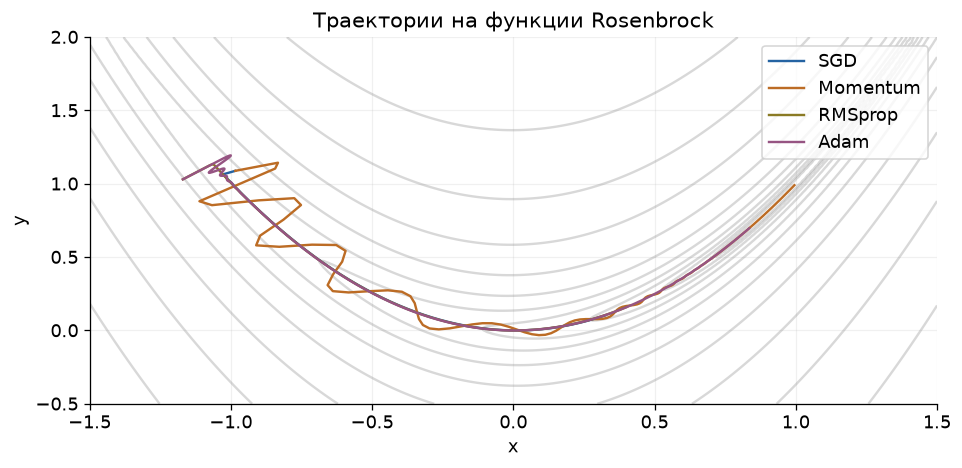

,optimizer,lr,loss,x,y
0,SGD,0.001,0.45480,0.32726,0.10401
1,Momentum,0.001,0.00003,0.99500,0.99000
2,RMSprop,0.003,0.35955,0.40247,0.16097
3,Adam,0.030,0.02733,0.83528,0.69713


In [2]:
trajectories = {}
rows = []
for name, lr in [
    ("SGD", 0.001),
    ("Momentum", 0.001),
    ("RMSprop", 0.003),
    ("Adam", 0.03),
]:
    p = torch.tensor([-1.2, 1.0], requires_grad=True)
    cls = {
        "SGD": torch.optim.SGD,
        "Momentum": lambda q, **kw: torch.optim.SGD(q, momentum=0.9, **kw),
        "RMSprop": torch.optim.RMSprop,
        "Adam": torch.optim.Adam,
    }[name]
    opt = cls([p], lr=lr)
    track = []
    for _ in range(1000):
        opt.zero_grad()
        loss = (1 - p[0]) ** 2 + 100 * (p[1] - p[0] ** 2) ** 2
        loss.backward()
        opt.step()
        track.append(p.detach().numpy().copy())
    trajectories[name] = np.array(track)
    rows.append(
        {
            "optimizer": name,
            "lr": lr,
            "loss": float(loss.detach()),
            "x": p[0].item(),
            "y": p[1].item(),
        }
    )
a, b = np.meshgrid(np.linspace(-1.5, 1.5, 200), np.linspace(-0.5, 2, 200))
plt.contour(
    a,
    b,
    (1 - a) ** 2 + 100 * (b - a * a) ** 2,
    levels=np.logspace(-1, 3, 12),
    colors="gray",
    alpha=0.3,
)
for name, p in trajectories.items():
    plt.plot(p[:, 0], p[:, 1], label=name)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Траектории на функции Rosenbrock")
plt.legend()
showfig("rosenbrock", OUT)
table(rows, OUT, "rosenbrock");

## Вариант 11. Маленькая, средняя и большая сеть

Регрессия y = sin(3x), x ∈ [−2, 2], шум σ = 0.3. Для каждого из пяти seed создаю 60 train- и 100 validation-точек. На одном seed все сети получают одинаковые данные. Bias² и variance считаю по пяти прогнозам на общей сетке относительно чистой функции.

,seed,width,parameters,train_MSE,best_val_MSE,clean_grid_MSE,seconds
0,11,8,97,0.05727,0.14784,0.05305,0.12875
1,11,32,1153,0.05337,0.14118,0.05246,0.16201
2,11,128,16897,0.05273,0.13144,0.04445,0.22191
3,12,8,97,0.07942,0.13189,0.02263,0.14803
4,12,32,1153,0.06038,0.11996,0.01460,0.16510
5,12,128,16897,0.05607,0.12042,0.01636,0.26996
6,13,8,97,0.06435,0.10645,0.01834,0.15128
7,13,32,1153,0.05085,0.10605,0.01774,0.16529
8,13,128,16897,0.04924,0.11177,0.02189,0.24351
9,14,8,97,0.04636,0.11491,0.02990,0.15686


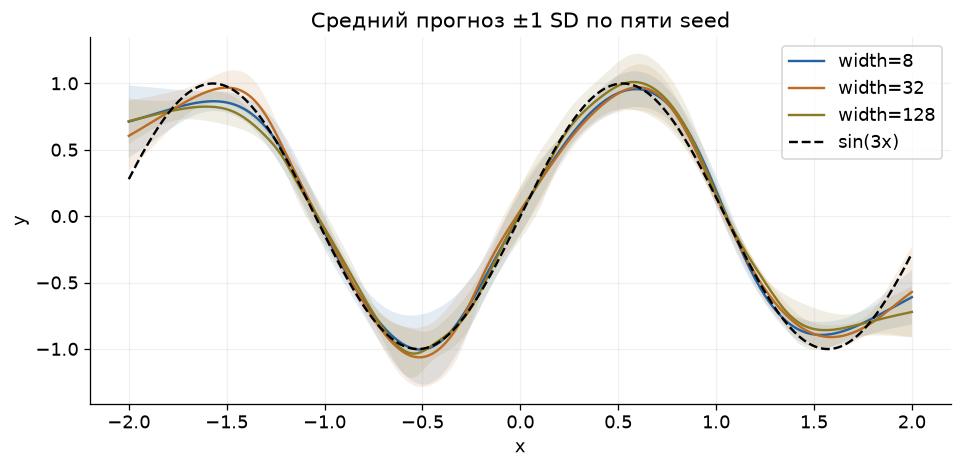

,width,bias_squared,variance_ddof0,expected_clean_MSE
0,8,0.00847,0.02012,0.02859
1,32,0.00643,0.02033,0.02676
2,128,0.01189,0.01852,0.03041


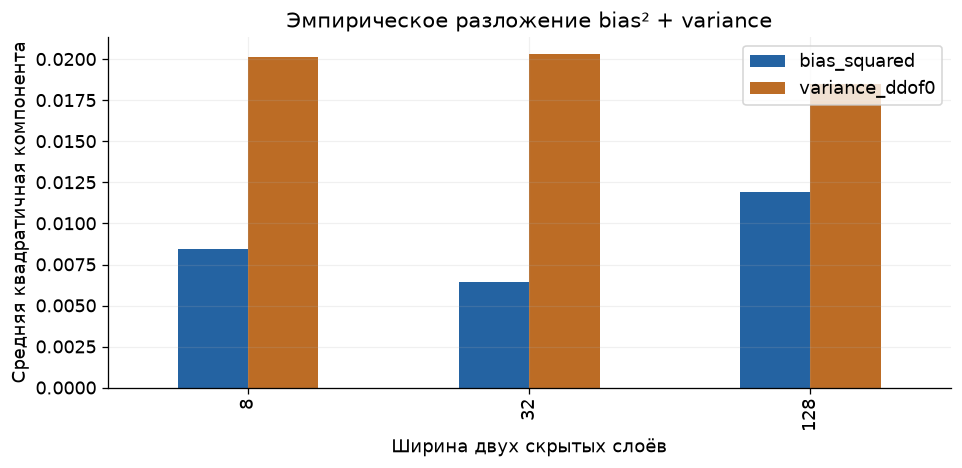

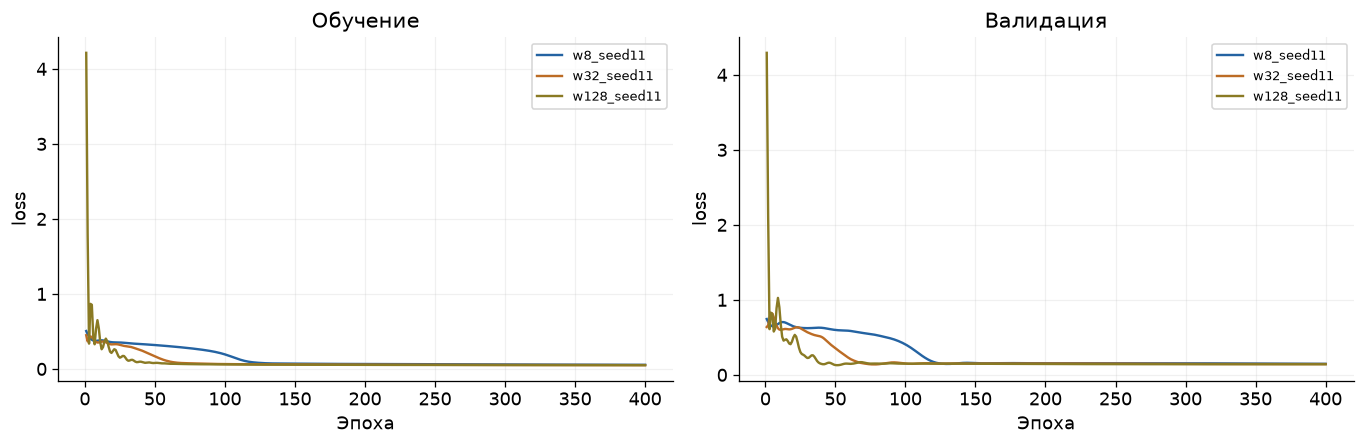

Тождество MSE=bias²+variance проверено численно по конечному ансамблю прогнозов и известной чистой функции. Это оценка по пяти выборкам/инициализациям. Добавление неустранимой дисперсии наблюдаемого шума дало бы ошибку предсказания новых шумных значений. Большая сеть при фиксированном бюджете обучения не обязана давать меньшую ошибку.

In [3]:
grid = tensor(np.linspace(-2, 2, 300, dtype="float32")[:, None])
truth = torch.sin(3 * grid).numpy().ravel()
predictions = {8: [], 32: [], 128: []}
rows = []
curves = {}
for seed in [11, 12, 13, 14, 15]:
    rng = np.random.default_rng(seed)
    x = tensor(rng.uniform(-2, 2, (60, 1)))
    y = torch.sin(3 * x) + 0.3 * tensor(rng.normal(size=(60, 1)))
    xv = tensor(rng.uniform(-2, 2, (100, 1)))
    yv = torch.sin(3 * xv) + 0.3 * tensor(rng.normal(size=(100, 1)))
    for width in [8, 32, 128]:
        seed_all(seed)
        m = MLP(1, 1, (width, width), activation="tanh")
        m, h, t = fit(
            m, (x, y), (xv, yv), epochs=400, batch=60, lr=0.01, task="regression"
        )
        curves[f"w{width}_seed{seed}"] = h
        with torch.no_grad():
            pred = m(grid).numpy().ravel()
        predictions[width].append(pred)
        rows.append(
            {
                "seed": seed,
                "width": width,
                "parameters": count_params(m),
                "train_MSE": h.iloc[-1].train_loss,
                "best_val_MSE": h.val_loss.min(),
                "clean_grid_MSE": mean_squared_error(truth, pred),
                "seconds": t,
            }
        )
df = table(rows, OUT)
decomp = []
for width, pp in predictions.items():
    pp = np.array(pp)
    avg = pp.mean(0)
    bias2 = np.mean((avg - truth) ** 2)
    variance = np.mean(pp.var(0))
    mse = np.mean((pp - truth) ** 2)
    assert np.isclose(mse, bias2 + variance)
    decomp.append(
        {
            "width": width,
            "bias_squared": bias2,
            "variance_ddof0": variance,
            "expected_clean_MSE": mse,
        }
    )
    plt.plot(grid.numpy().ravel(), avg, label=f"width={width}")
    plt.fill_between(grid.numpy().ravel(), avg - pp.std(0), avg + pp.std(0), alpha=0.12)
plt.plot(grid.numpy().ravel(), truth, "k--", label="sin(3x)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Средний прогноз ±1 SD по пяти seed")
plt.legend()
showfig("capacity_predictions", OUT)
dc = table(decomp, OUT, "bias_variance")
dc.set_index("width")[["bias_squared", "variance_ddof0"]].plot.bar()
plt.xlabel("Ширина двух скрытых слоёв")
plt.ylabel("Средняя квадратичная компонента")
plt.title("Эмпирическое разложение bias² + variance")
showfig("bias_variance", OUT)
histories(
    {k: v for k, v in curves.items() if k.endswith("seed11")}, OUT, "capacity_curves"
)
note(
    "Тождество MSE=bias²+variance проверено численно по конечному ансамблю прогнозов и известной чистой функции. Это оценка по пяти выборкам/инициализациям. Добавление неустранимой дисперсии наблюдаемого шума дало бы ошибку предсказания новых шумных значений. Большая сеть при фиксированном бюджете обучения не обязана давать меньшую ошибку."
)

## Регуляризация и абляция

Сравниваю исходную сеть, dropout, weight decay и их сочетание. Затем проверяю три learning rate.

,configuration,best_val_MSE,train_MSE
0,baseline,0.10509,0.09233
1,dropout,0.11457,0.12712
2,weight_decay,0.17659,0.17503
3,both,0.19484,0.20874


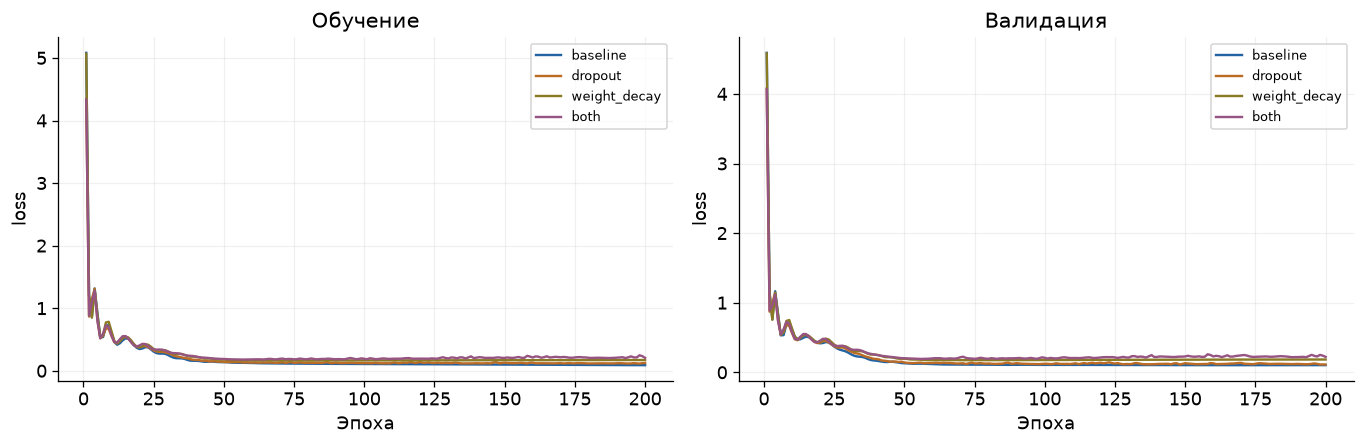

Сопоставление кривых train/validation позволяет отличить недостаточную оптимизацию от переобучения. Регуляризация может уменьшить variance и одновременно увеличить bias; итоговый компромисс оценивается на независимых данных.

In [4]:
rows = []
curves = {}
for name, drop, wd in [
    ("baseline", 0.0, 0.0),
    ("dropout", 0.2, 0.0),
    ("weight_decay", 0.0, 0.01),
    ("both", 0.2, 0.01),
]:
    seed_all()
    m = MLP(1, 1, (128, 128), activation="tanh", dropout=drop)
    m, h, t = fit(
        m,
        (x, y),
        (xv, yv),
        epochs=200,
        batch=60,
        lr=0.01,
        task="regression",
        weight_decay=wd,
    )
    rows.append(
        {
            "configuration": name,
            "best_val_MSE": h.val_loss.min(),
            "train_MSE": h.iloc[-1].train_loss,
        }
    )
    curves[name] = h
table(rows, OUT, "regularization_ablation")
histories(curves, OUT, "ablation_curves")
note(
    "Сопоставление кривых train/validation позволяет отличить недостаточную оптимизацию от переобучения. Регуляризация может уменьшить variance и одновременно увеличить bias; итоговый компромисс оценивается на независимых данных."
)

## Ответы на контрольные вопросы

1. Переобучение проявляется расхождением train/validation; неудачный learning rate может оставлять обе ошибки высокими либо нестабильными.

2. Adam быстрее снижает loss в некоторых задачах, но итоговое обобщение зависит от данных, регуляризации, шага и бюджета.

3. В train dropout применяет случайную маску с масштабом 1/(1−p); в eval маскирование отключено.

4. Seed фиксирует воспроизводимые источники случайности; сравнение нескольких seed показывает ограничение одного запуска.

5. Аугментация должна сохранять целевой смысл объекта, иначе она создаёт неверно размеченные примеры.